In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [4]:
import pandas as pd
import zipfile
import io
import urllib.request

url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

response = urllib.request.urlopen(url)
outer_zip = zipfile.ZipFile(io.BytesIO(response.read()))

# Extract the ZIP contained inside the downloaded ZIP
inner_name = next(
    name for name in outer_zip.namelist()
    if name.endswith("bank.zip")
)
inner_bytes = outer_zip.read(inner_name)

with zipfile.ZipFile(io.BytesIO(inner_bytes)) as inner_zip:
    print("Files found:", inner_zip.namelist())

    with inner_zip.open("bank-full.csv") as f:
        df = pd.read_csv(f, sep=";")

print("Dataset shape:", df.shape)
display(df.head())

Files found: ['bank-full.csv', 'bank-names.txt', 'bank.csv']
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [5]:
# Check dataset information
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check target distribution
print("\nTarget distribution:")
print(df["y"].value_counts())

# Check summary statistics
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

Missing values:
age          0
job          0
marital      0
education    0
default      0
balance

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


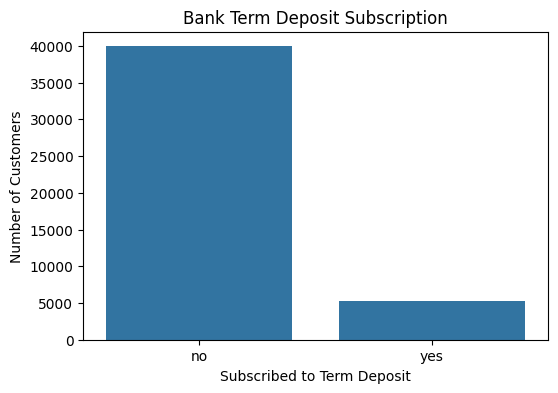

In [6]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="y")

plt.title("Bank Term Deposit Subscription")
plt.xlabel("Subscribed to Term Deposit")
plt.ylabel("Number of Customers")

plt.show()

In [7]:
# Separate features and target
X = df.drop("y", axis=1)
y = df["y"].map({"no": 0, "yes": 1})

# Convert categorical variables into numeric features
X = pd.get_dummies(X, drop_first=True)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (45211, 42)
Target shape: (45211,)


,age,balance,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,58,2143,5,261,1,-1,0,False,False,False,...,False,False,False,True,False,False,False,False,False,True
1,44,29,5,151,1,-1,0,False,False,False,...,False,False,False,True,False,False,False,False,False,True
2,33,2,5,76,1,-1,0,False,True,False,...,False,False,False,True,False,False,False,False,False,True
3,47,1506,5,92,1,-1,0,True,False,False,...,False,False,False,True,False,False,False,False,False,True
4,33,1,5,198,1,-1,0,False,False,False,...,False,False,False,True,False,False,False,False,False,True


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 36168
Testing samples: 9043


In [9]:
# Create the Decision Tree Classifier
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [10]:
# Predict on the test data
y_pred = model.predict(X_test)

print("First 10 predictions:", y_pred[:10])
print("First 10 actual values:", y_test.iloc[:10].values)

First 10 predictions: [0 0 0 0 0 0 0 1 0 0]
First 10 actual values: [0 0 0 0 0 0 0 1 0 0]


In [11]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4f}")
print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Subscription", "Subscription"]
))

Model Accuracy: 0.8984
Model Accuracy: 89.84%

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.91      0.98      0.94      7985
   Subscription       0.64      0.30      0.41      1058

       accuracy                           0.90      9043
      macro avg       0.78      0.64      0.68      9043
   weighted avg       0.88      0.90      0.88      9043



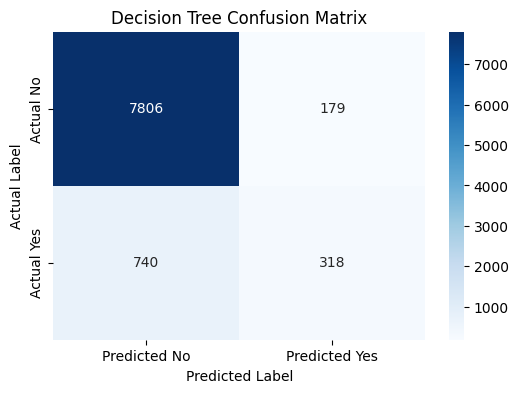

In [12]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

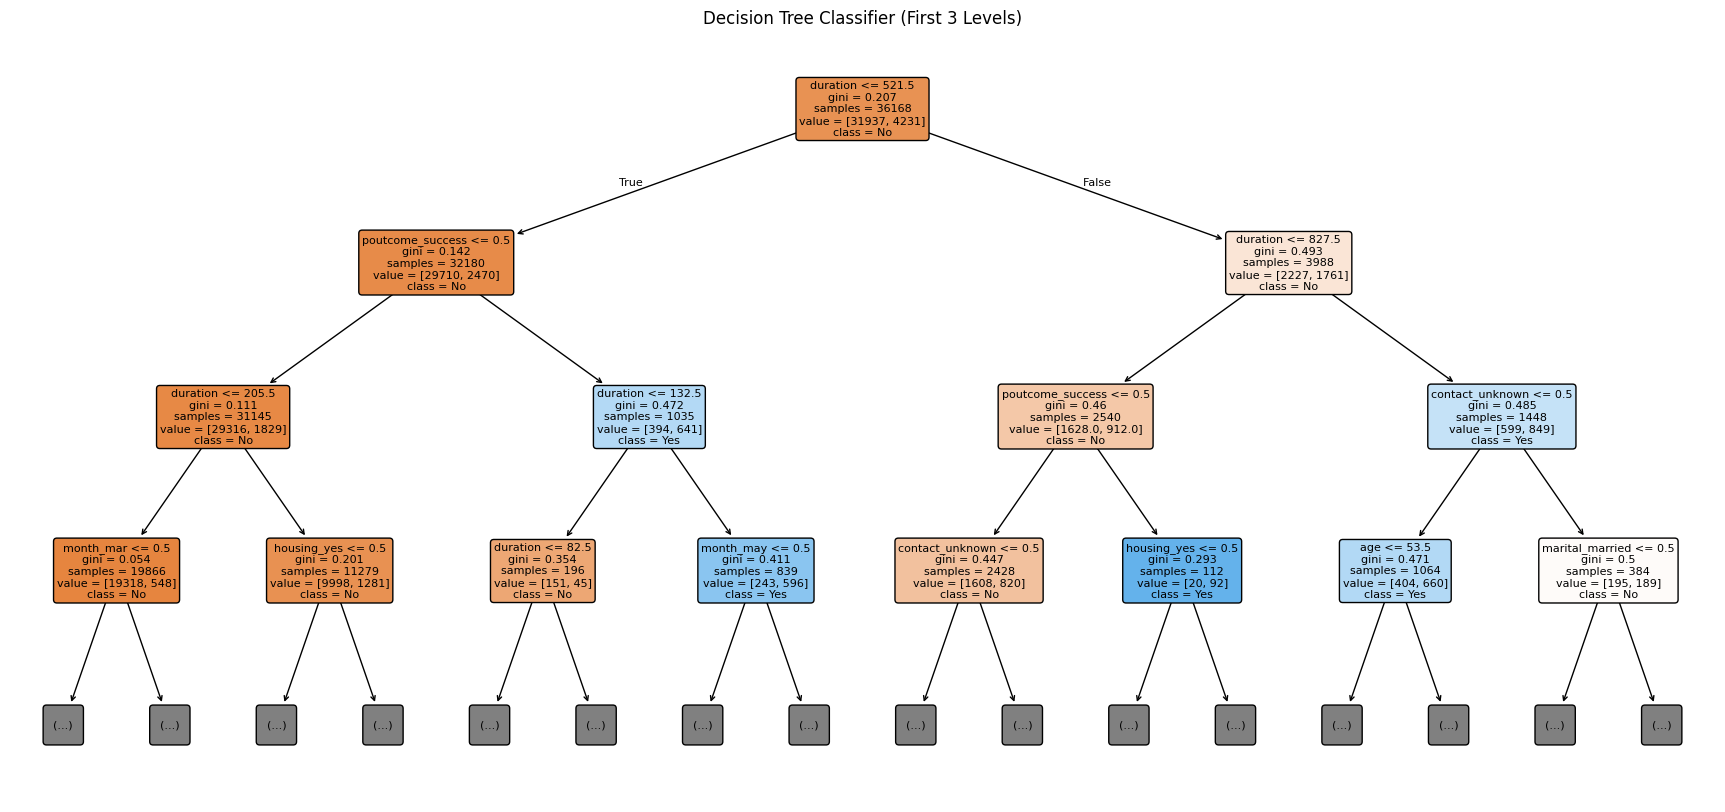

In [13]:
plt.figure(figsize=(22, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Classifier (First 3 Levels)")
plt.show()

### Conclusion

A Decision Tree Classifier was developed using the Bank Marketing dataset to predict whether a customer would subscribe to a term deposit. The dataset was prepared by encoding categorical features and splitting the data into training and testing sets. The model achieved an accuracy of **89.84%**. However, the recall for customers who subscribed was only **30%**, indicating that the model missed many potential subscribers. This suggests that further improvements, such as class balancing and hyperparameter tuning, may help improve prediction performance.
